<a href="https://colab.research.google.com/github/Ophelie4/pfizer-document-intelligence/blob/main/project-03-data-extraction-from-documents/notebooks/Ophelie_SDF_Field_Extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Extract Key Dates & Fields from SDF using Regex, Anchor Phrases & Bounding Boxes
Downloads `sample-sdf-document.pdf`, locates labeled fields (Date of Manufacture, Expiration Date, Lot Number, Product Article Number, Product Description, Vendor) using anchor-phrase search + PyMuPDF bounding boxes, validates dates with regex, extracts the test-results table with `page.find_tables()`, and draws boxes around extracted fields with OpenCV.

In [ ]:
!pip install -q pymupdf gdown opencv-python-headless
import fitz
import re
import json
import gdown
import cv2
import numpy as np
from matplotlib import pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 37.3 MB/s eta 0:00:00


In [ ]:
# Download the sample SDF document provided for this task
file_id = '1oOR50D8F3Deask7aT2HbXQZhw0u1hvcg'
gdown.download(f'https://drive.google.com/uc?id={file_id}', 'sample_sdf_document.pdf', quiet=False)

doc = fitz.open('sample_sdf_document.pdf')
print(f"Total Pages: {doc.page_count}")

Downloading...
From: https://drive.google.com/uc?id=1oOR50D8F3Deask7aT2HbXQZhw0u1hvcg
To: /content/sample_sdf_document.pdf
100%|██████████| 147k/147k [00:00<00:00, 66.2MB/s]

Total Pages: 3


## Step 1: Locate labeled fields using anchor phrases + bounding boxes

In [ ]:
anchor_phrases = [
    "Date of Manufacture:",
    "Expiration Date:",
    "Lot Number:",
    "Product Article Number:",
    "Product Description:",
]

date_pattern = re.compile(r'\b\d{8}\b')  # e.g. 20210126 (YYYYMMDD)

extracted_fields = []

for page_num in range(len(doc)):
    page = doc[page_num]
    words = page.get_text("words")
    for anchor in anchor_phrases:
        rects = page.search_for(anchor)
        for r in rects:
            # Find words on the same line, to the right of the anchor
            candidates = [w for w in words if w[1] < r.y1 and w[3] > r.y0 and w[0] >= r.x1 - 2]
            candidates.sort(key=lambda w: w[0])
            value_words = []
            if candidates:
                first_line = candidates[0][6]
                for w in candidates:
                    if w[6] == first_line:
                        value_words.append(w[4])
                    else:
                        break
            value_text = " ".join(value_words)
            label = anchor.rstrip(":")
            field = {
                "label": label,
                "text": f"{label}: {value_text}",
                "page": page_num + 1,
                "bbox": [round(r.x0, 2), round(r.y0, 2), round(r.x1, 2), round(r.y1, 2)],
            }
            if "Date" in label:
                m = date_pattern.search(value_text)
                field["regex_validated_date"] = m.group(0) if m else None
            extracted_fields.append(field)

# Vendor name from the letterhead on page 1
vendor_rects = doc[0].search_for("Cytiva")
if vendor_rects:
    r = vendor_rects[0]
    extracted_fields.append({
        "label": "Vendor Name",
        "text": "Vendor Name: Cytiva",
        "page": 1,
        "bbox": [round(r.x0, 2), round(r.y0, 2), round(r.x1, 2), round(r.y1, 2)],
    })

print(f"Extracted {len(extracted_fields)} fields:\n")
for f in extracted_fields:
    print(json.dumps(f, indent=2))

Extracted 11 fields:

{
  "label": "Date of Manufacture",
  "text": "Date of Manufacture: 20210126 Product Description: High Flow Gradient C, Modified, \u00c4KTATM ready",
  "page": 2,
  "bbox": [
    53.64,
    132.12,
    143.33,
    144.27
  ],
  "regex_validated_date": "20210126"
}
{
  "label": "Expiration Date",
  "text": "Expiration Date: 20230126",
  "page": 2,
  "bbox": [
    53.64,
    153.72,
    120.82,
    165.87
  ],
  "regex_validated_date": "20230126"
}
{
  "label": "Lot Number",
  "text": "Lot Number: 17242818",
  "page": 2,
  "bbox": [
    53.64,
    110.52,
    105.78,
    122.67
  ]
}
{
  "label": "Product Article Number",
  "text": "Product Article Number: 29 1846 12",
  "page": 2,
  "bbox": [
    257.42,
    110.52,
    359.26,
    122.67
  ]
}
{
  "label": "Product Description",
  "text": "Product Description: High Flow Gradient C, Modified, \u00c4KTATM ready",
  "page": 2,
  "bbox": [
    257.42,
    142.92,
    342.73,
    155.07
  ]
}
{
  "label": "Date of Manu

## Step 2: Extract structured table data using PyMuPDF's table detection

In [ ]:
tables_data = []
for page_num in range(len(doc)):
    page = doc[page_num]
    tabs = page.find_tables()
    for t_idx, tab in enumerate(tabs.tables):
        rows = tab.extract()
        tables_data.append({
            "page": page_num + 1,
            "table_index": t_idx,
            "bbox": [round(v, 2) for v in tab.bbox],
            "rows": rows,
        })

print(f"Found {len(tables_data)} table(s)\n")
for t in tables_data:
    print(f"--- Page {t['page']}, table {t['table_index']} (bbox {t['bbox']}) ---")
    for row in t['rows']:
        print(row)
    print()

Consider using the pymupdf_layout package for a greatly improved page layout analysis.
Found 1 table(s)

--- Page 3, table 0 (bbox [50.0, 343.0, 530.0, 497.0]) ---
['Description', 'Test Method', 'Result']
['Autoclave - Pump tubing', '121C > 15 min', 'Conforms']
['Gamma Irradiation - Inlets', '25.0 - 40.0 kGy', 'Conforms']
['Flow Rate Test', 'Per SOP-QC-042', 'Pass']
['Pressure Integrity', 'Max 0.5 bar, 5 min hold', 'Pass']
['Visual Inspection', 'No defects visible', 'Pass']
['Package Integrity', 'Sealed, no damage', 'Pass']



## Step 3: Save structured output

In [ ]:
with open('sdf_extracted_fields.json', 'w') as f:
    json.dump(extracted_fields, f, indent=2)

with open('sdf_extracted_tables.json', 'w') as f:
    json.dump(tables_data, f, indent=2)

print("Saved sdf_extracted_fields.json and sdf_extracted_tables.json")

Saved sdf_extracted_fields.json and sdf_extracted_tables.json


## Step 4 (Optional): Visualize extracted fields with OpenCV bounding boxes

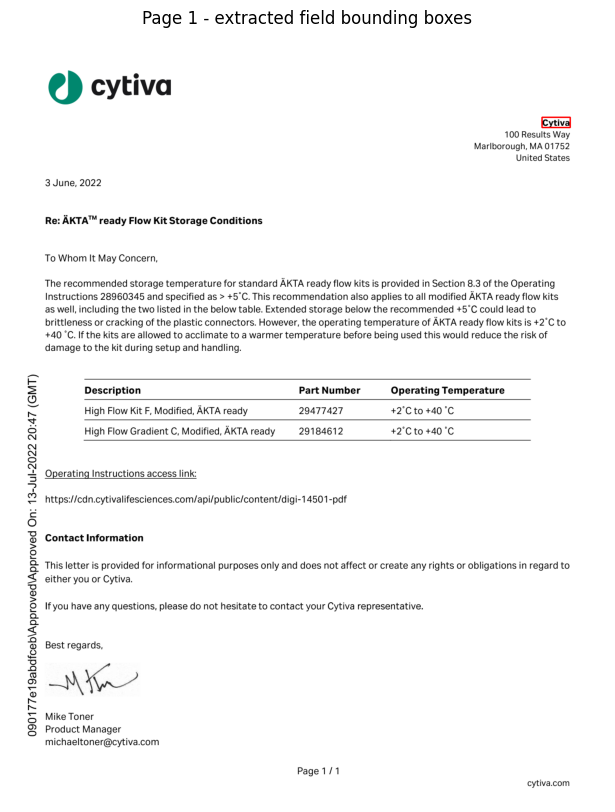

Saved page1_annotated.jpg


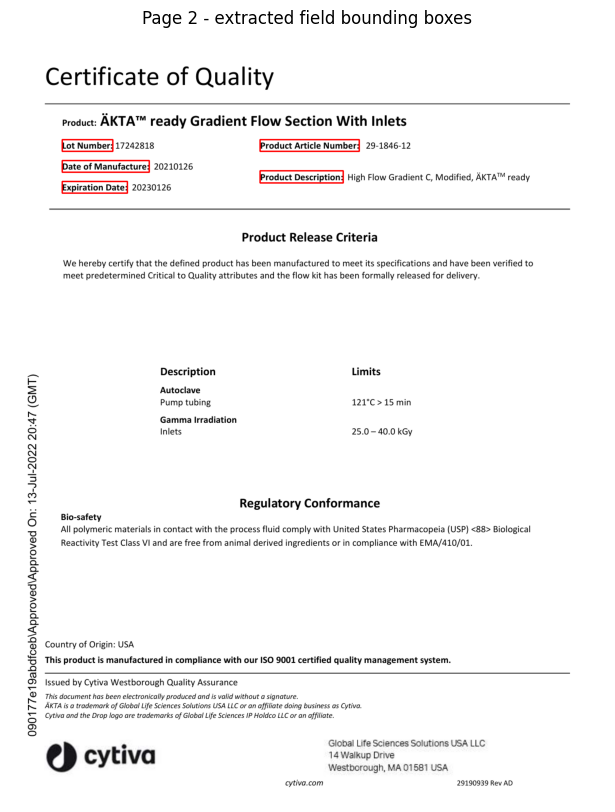

Saved page2_annotated.jpg


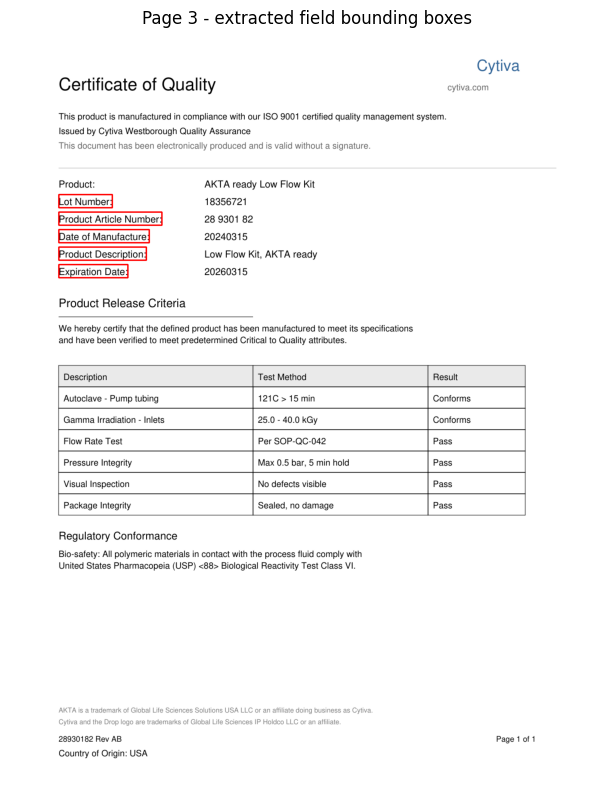

Saved page3_annotated.jpg


In [ ]:
zoom = 2
for page_num in range(len(doc)):
    page_fields = [f for f in extracted_fields if f['page'] == page_num + 1]
    if not page_fields:
        continue
    page = doc[page_num]
    pix = page.get_pixmap(matrix=fitz.Matrix(zoom, zoom))
    img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    for f in page_fields:
        x0, y0, x1, y1 = f['bbox']
        cv2.rectangle(img, (int(x0 * zoom), int(y0 * zoom)), (int(x1 * zoom), int(y1 * zoom)), (0, 0, 255), 2)
    out_name = f'page{page_num + 1}_annotated.jpg'
    cv2.imwrite(out_name, img)
    plt.figure(figsize=(8, 10))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title(f'Page {page_num + 1} - extracted field bounding boxes')
    plt.show()
    print(f"Saved {out_name}")